# Colab 2.2 — De ecuaciones a escenarios

**Proyecto:** Análisis del comportamiento de compra en sesiones de comercio electrónico  
**Dataset:** Online Shoppers Purchasing Intention Dataset  
**Autor:** Octavio Vieyra Orozco

## Objetivo

Construir indicadores que no aparecen directamente en el dataset y utilizarlos para analizar escenarios deterministas y probabilísticos relacionados con la compra.

## Pregunta general

> ¿Cómo cambia la cantidad esperada de compras cuando se modifica hipotéticamente la tasa de compra de las sesiones con baja interacción?

El análisis no busca predecir individualmente si una persona comprará. Se utilizará el comportamiento histórico como referencia para explorar posibles resultados bajo distintos escenarios.

## 0. Preparación del entorno

In [1]:
!pip -q install kagglehub

In [2]:
import warnings
warnings.filterwarnings("ignore")

import os
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import kagglehub

pd.set_option("display.max_columns", None)
pd.set_option("display.float_format", lambda x: f"{x:,.2f}")
sns.set_theme(style="whitegrid")

## 1. Carga y preparación del dataset

In [3]:
# Descargar el mismo dataset utilizado en Colab 2.1
path = Path(
    kagglehub.dataset_download(
        "imakash3011/online-shoppers-purchasing-intention-dataset"
    )
)

csv_path = next(path.rglob("*.csv"))
df = pd.read_csv(csv_path)

print("Filas originales:", df.shape[0])
print("Columnas originales:", df.shape[1])
df.head()

Using Colab cache for faster access to the 'online-shoppers-purchasing-intention-dataset' dataset.
Filas originales: 12330
Columnas originales: 18


,Administrative,Administrative_Duration,Informational,Informational_Duration,ProductRelated,ProductRelated_Duration,BounceRates,ExitRates,PageValues,SpecialDay,Month,OperatingSystems,Browser,Region,TrafficType,VisitorType,Weekend,Revenue
0,0,0.00,0,0.00,1,0.00,0.20,0.20,0.00,0.00,Feb,1,1,1,1,Returning_Visitor,False,False
1,0,0.00,0,0.00,2,64.00,0.00,0.10,0.00,0.00,Feb,2,2,1,2,Returning_Visitor,False,False
2,0,0.00,0,0.00,1,0.00,0.20,0.20,0.00,0.00,Feb,4,1,9,3,Returning_Visitor,False,False
3,0,0.00,0,0.00,2,2.67,0.05,0.14,0.00,0.00,Feb,3,2,2,4,Returning_Visitor,False,False
4,0,0.00,0,0.00,10,627.50,0.02,0.05,0.00,0.00,Feb,3,3,1,4,Returning_Visitor,True,False


In [4]:
# Mantener el mismo criterio de limpieza de Colab 2.1
df_copy = df.drop_duplicates().copy()

# Variables auxiliares
df_copy["Administrative_Duration_min"] = df_copy["Administrative_Duration"] / 60
df_copy["Informational_Duration_min"] = df_copy["Informational_Duration"] / 60
df_copy["ProductRelated_Duration_min"] = df_copy["ProductRelated_Duration"] / 60

df_copy["Total_Duration_sec"] = (
    df_copy["Administrative_Duration"]
    + df_copy["Informational_Duration"]
    + df_copy["ProductRelated_Duration"]
)
df_copy["Total_Duration_min"] = df_copy["Total_Duration_sec"] / 60

df_copy["Total_Pages"] = (
    df_copy["Administrative"]
    + df_copy["Informational"]
    + df_copy["ProductRelated"]
)

df_copy["Revenue_num"] = df_copy["Revenue"].astype(int)

print("Filas después de eliminar duplicados:", len(df_copy))
df_copy[["Total_Pages", "Total_Duration_min", "Revenue"]].head()

Filas después de eliminar duplicados: 12205


,Total_Pages,Total_Duration_min,Revenue
0,1,0.00,False
1,2,1.07,False
2,1,0.00,False
3,2,0.04,False
4,10,10.46,False


## 2. Construcción de nuevos indicadores

Se construirán dos indicadores mediante ecuaciones:

### Páginas visitadas por minuto

$$
\text{Páginas por minuto}=
\frac{\text{Total de páginas visitadas}}
{\text{Duración total en minutos}}
$$

Este indicador representa el ritmo de navegación de la sesión.

### Participación de páginas de producto

$$
\text{Participación de producto}=
\frac{\text{Páginas de producto}}
{\text{Total de páginas}}\times 100
$$

Este indicador muestra qué porcentaje de la navegación se concentró en productos.

In [5]:
# Evitar divisiones entre cero
df_copy["Pages_per_min"] = np.where(
    df_copy["Total_Duration_min"] > 0,
    df_copy["Total_Pages"] / df_copy["Total_Duration_min"],
    np.nan
)

df_copy["Product_Page_Share_pct"] = np.where(
    df_copy["Total_Pages"] > 0,
    df_copy["ProductRelated"] / df_copy["Total_Pages"] * 100,
    0
)

df_copy[[
    "Total_Pages",
    "Total_Duration_min",
    "Pages_per_min",
    "Product_Page_Share_pct"
]].describe(percentiles=[0.25, 0.50, 0.75, 0.95]).round(2)

,Total_Pages,Total_Duration_min,Pages_per_min,Product_Page_Share_pct
count,"12,205.00","12,205.00","11,610.00","12,205.00"
mean,34.89,22.06,2.60,90.41
std,46.63,34.06,4.09,14.23
min,0.00,0.00,0.04,0.00
25%,9.00,3.86,1.28,85.71
50%,20.00,11.52,1.94,96.15
75%,42.00,27.40,2.96,100.00
95%,117.00,76.96,6.09,100.00
max,746.00,"1,165.36",200.00,100.00


### Interpretación

Los indicadores permiten comparar sesiones que tienen duraciones y cantidades de páginas diferentes. `Pages_per_min` representa la velocidad con la que se recorrió el sitio, mientras que `Product_Page_Share_pct` permite conocer si la sesión se concentró principalmente en la revisión de productos. Los valores extremos deben interpretarse con cautela, especialmente cuando una sesión tiene una duración muy corta.

## 3. Construcción de niveles de navegación

In [6]:
# Crear tres grupos con cantidades similares de sesiones
df_copy["Navigation_Level"] = pd.qcut(
    df_copy["Total_Pages"],
    q=3,
    labels=["Baja", "Media", "Alta"]
)

navigation_profile = (
    df_copy.groupby("Navigation_Level", observed=True)
    .agg(
        sessions=("Revenue", "size"),
        average_pages=("Total_Pages", "mean"),
        average_duration_min=("Total_Duration_min", "mean"),
        average_product_share=("Product_Page_Share_pct", "mean"),
        purchase_rate=("Revenue_num", "mean")
    )
)

navigation_profile["purchase_rate_pct"] = navigation_profile["purchase_rate"] * 100
navigation_profile.round(2)

,sessions,average_pages,average_duration_min,average_product_share,purchase_rate,purchase_rate_pct
Navigation_Level,,,,,,
Baja,4155,6.05,3.98,91.01,0.07,6.96
Media,4047,21.46,14.35,88.60,0.17,17.07
Alta,4003,78.41,48.61,91.62,0.23,23.18


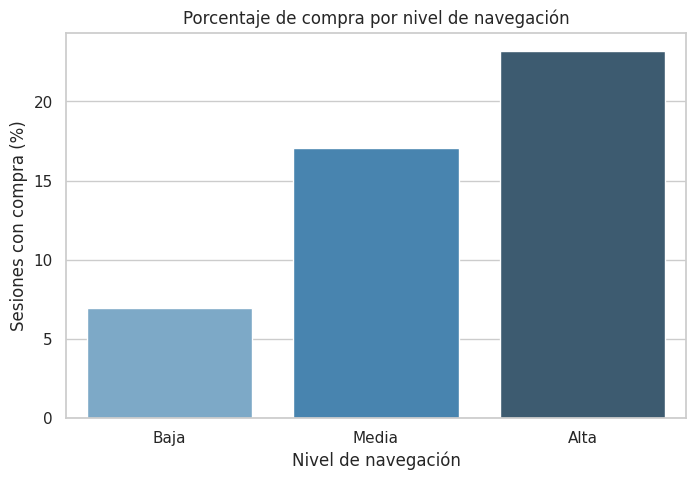

In [7]:
plt.figure(figsize=(8, 5))

sns.barplot(
    data=navigation_profile.reset_index(),
    x="Navigation_Level",
    y="purchase_rate_pct",
    palette="Blues_d"
)

plt.title("Porcentaje de compra por nivel de navegación")
plt.xlabel("Nivel de navegación")
plt.ylabel("Sesiones con compra (%)")
plt.show()

### Interpretación

La tabla y la gráfica permiten comprobar si el porcentaje de compra cambia conforme aumenta la cantidad de páginas visitadas. Esta relación se utilizará para definir un escenario dirigido a las sesiones de baja navegación. La asociación encontrada es descriptiva y no demuestra que visitar más páginas cause directamente una compra.

## 4. Construcción del escenario determinista

La cantidad esperada de compras puede calcularse mediante:

$$
\text{Compras esperadas}=
\text{Número de sesiones}\times\text{Tasa de compra}
$$

Se compararán dos escenarios para cada 1,000 sesiones de baja navegación:

- **Escenario base:** conserva la tasa histórica de compra.
- **Escenario alternativo:** supone una mejora hipotética de 3 puntos porcentuales en esa tasa.

La mejora de 3 puntos es un supuesto para explorar el escenario, no una predicción ni una relación causal demostrada.

In [8]:
sessions_scenario = 1000
improvement_pp = 3

base_rate_low = navigation_profile.loc["Baja", "purchase_rate"]
alternative_rate_low = min(base_rate_low + improvement_pp / 100, 1)

expected_base = sessions_scenario * base_rate_low
expected_alternative = sessions_scenario * alternative_rate_low

deterministic_scenario = pd.DataFrame({
    "Scenario": ["Base", "Alternative"],
    "Purchase_rate_pct": [base_rate_low * 100, alternative_rate_low * 100],
    "Expected_purchases": [expected_base, expected_alternative]
}).round(2)

deterministic_scenario

,Scenario,Purchase_rate_pct,Expected_purchases
0,Base,6.96,69.55
1,Alternative,9.96,99.55


In [9]:
additional_expected_purchases = expected_alternative - expected_base

print(
    "Compras adicionales esperadas por cada",
    f"{sessions_scenario:,}",
    "sesiones de baja navegación:",
    round(additional_expected_purchases, 2)
)

Compras adicionales esperadas por cada 1,000 sesiones de baja navegación: 30.0


### Interpretación

El escenario determinista muestra el resultado promedio que se obtendría si la tasa alternativa se cumpliera exactamente. Sin embargo, en grupos reales de sesiones el número de compras puede variar, incluso si la probabilidad permanece constante. Por ello, el siguiente paso incorpora incertidumbre mediante simulación.

## 5. Primera simulación: 100 sesiones

In [10]:
rng = np.random.default_rng(42)

n_sessions = 100

base_events = rng.binomial(
    n=1,
    p=base_rate_low,
    size=n_sessions
)

alternative_events = rng.binomial(
    n=1,
    p=alternative_rate_low,
    size=n_sessions
)

first_simulation = pd.DataFrame({
    "Scenario": ["Base", "Alternative"],
    "Sessions": [n_sessions, n_sessions],
    "Purchases_obtained": [base_events.sum(), alternative_events.sum()]
})

first_simulation

,Scenario,Sessions,Purchases_obtained
0,Base,100,4
1,Alternative,100,11


### Interpretación

Cada sesión se representa mediante un evento binario: 1 si ocurre una compra y 0 si no ocurre. El resultado puede ser distinto cada vez que se simula, porque no sabemos de antemano cuáles sesiones terminarán en compra. Una sola simulación no es suficiente para evaluar un escenario, por lo que es necesario repetirla muchas veces.

## 6. Repetición del escenario

In [11]:
n_simulations = 2000
n_sessions = 100

base_simulations = rng.binomial(
    n=n_sessions,
    p=base_rate_low,
    size=n_simulations
)

alternative_simulations = rng.binomial(
    n=n_sessions,
    p=alternative_rate_low,
    size=n_simulations
)

simulation_summary = pd.DataFrame({
    "Scenario": ["Base", "Alternative"],
    "Average_purchases": [base_simulations.mean(), alternative_simulations.mean()],
    "Standard_deviation": [base_simulations.std(), alternative_simulations.std()],
    "Percentile_5": [np.percentile(base_simulations, 5), np.percentile(alternative_simulations, 5)],
    "Median": [np.median(base_simulations), np.median(alternative_simulations)],
    "Percentile_95": [np.percentile(base_simulations, 95), np.percentile(alternative_simulations, 95)]
}).round(2)

simulation_summary

,Scenario,Average_purchases,Standard_deviation,Percentile_5,Median,Percentile_95
0,Base,7.00,2.60,3.00,7.00,11.00
1,Alternative,9.92,2.99,5.00,10.00,15.00


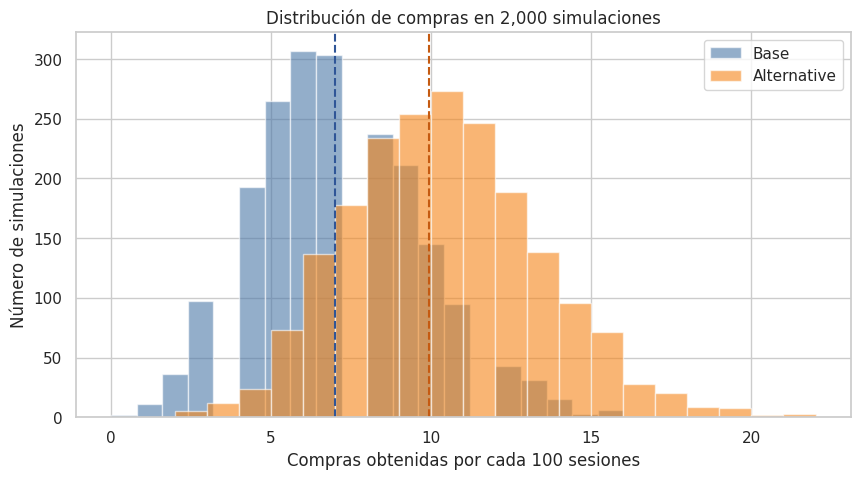

In [12]:
plt.figure(figsize=(10, 5))

plt.hist(
    base_simulations,
    bins=20,
    alpha=0.60,
    label="Base",
    color="#4C78A8"
)

plt.hist(
    alternative_simulations,
    bins=20,
    alpha=0.60,
    label="Alternative",
    color="#F58518"
)

plt.axvline(base_simulations.mean(), color="#2F5597", linestyle="--")
plt.axvline(alternative_simulations.mean(), color="#C55A11", linestyle="--")

plt.title("Distribución de compras en 2,000 simulaciones")
plt.xlabel("Compras obtenidas por cada 100 sesiones")
plt.ylabel("Número de simulaciones")
plt.legend()
plt.show()

### Interpretación

Las distribuciones muestran que no existe un único resultado posible. El escenario alternativo desplaza la cantidad promedio de compras hacia valores superiores, pero ambos escenarios pueden superponerse debido a la variabilidad natural. Los percentiles 5 y 95 muestran un intervalo donde se concentra aproximadamente el 90% de los resultados simulados.

## 7. El contexto de la sesión

In [13]:
visitor_profile = (
    df_copy.groupby("VisitorType")
    .agg(
        sessions=("Revenue", "size"),
        average_pages=("Total_Pages", "mean"),
        average_duration_min=("Total_Duration_min", "mean"),
        purchase_rate_pct=("Revenue_num", lambda x: x.mean() * 100)
    )
    .round(2)
    .sort_values("purchase_rate_pct", ascending=False)
)

visitor_profile

,sessions,average_pages,average_duration_min,purchase_rate_pct
VisitorType,,,,
New_Visitor,1693,20.95,12.47,24.93
Other,81,14.77,11.28,19.75
Returning_Visitor,10431,37.31,23.70,14.09


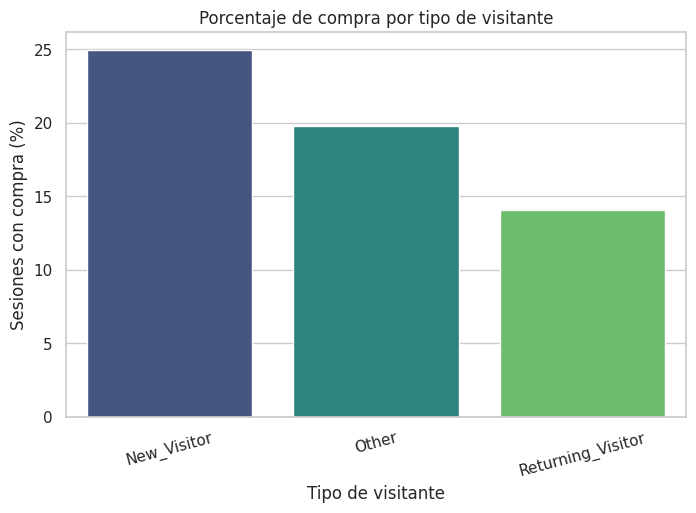

In [14]:
plt.figure(figsize=(8, 5))

sns.barplot(
    data=visitor_profile.reset_index(),
    x="VisitorType",
    y="purchase_rate_pct",
    palette="viridis"
)

plt.title("Porcentaje de compra por tipo de visitante")
plt.xlabel("Tipo de visitante")
plt.ylabel("Sesiones con compra (%)")
plt.xticks(rotation=15)
plt.show()

### Interpretación

La tasa general de compra no describe por completo a todos los usuarios. El tipo de visitante presenta contextos distintos, por lo que los resultados de un escenario pueden cambiar según la composición de las sesiones analizadas. Esto muestra por qué una misma mejora hipotética no necesariamente tendría el mismo efecto en todos los grupos.

## 8. Simulación de una cartera de 1,000 sesiones

En este escenario se conserva la proporción histórica de sesiones de navegación baja, media y alta. Se simula la cantidad total de compras bajo dos condiciones:

- **Base:** tasas históricas de los tres niveles.
- **Alternativa:** incremento de 3 puntos porcentuales únicamente en las sesiones de navegación baja.

In [15]:
portfolio_size = 1000

segment_counts = (
    navigation_profile["sessions"] / navigation_profile["sessions"].sum() * portfolio_size
).round().astype(int)

# Ajuste para conservar exactamente 1,000 sesiones
segment_counts.iloc[0] += portfolio_size - segment_counts.sum()

segment_rates = navigation_profile["purchase_rate"].copy()
alternative_segment_rates = segment_rates.copy()
alternative_segment_rates.loc["Baja"] = min(
    alternative_segment_rates.loc["Baja"] + improvement_pp / 100,
    1
)

portfolio_definition = pd.DataFrame({
    "Sessions": segment_counts,
    "Base_rate_pct": segment_rates * 100,
    "Alternative_rate_pct": alternative_segment_rates * 100
}).round(2)

portfolio_definition

,Sessions,Base_rate_pct,Alternative_rate_pct
Navigation_Level,,,
Baja,340,6.96,9.96
Media,332,17.07,17.07
Alta,328,23.18,23.18


In [16]:
n_portfolio_simulations = 2000
portfolio_base = np.zeros(n_portfolio_simulations, dtype=int)
portfolio_alternative = np.zeros(n_portfolio_simulations, dtype=int)

for level in segment_counts.index:
    portfolio_base += rng.binomial(
        n=segment_counts.loc[level],
        p=segment_rates.loc[level],
        size=n_portfolio_simulations
    )

    portfolio_alternative += rng.binomial(
        n=segment_counts.loc[level],
        p=alternative_segment_rates.loc[level],
        size=n_portfolio_simulations
    )

portfolio_summary = pd.DataFrame({
    "Scenario": ["Base", "Alternative"],
    "Average_purchases": [portfolio_base.mean(), portfolio_alternative.mean()],
    "Minimum_simulated": [portfolio_base.min(), portfolio_alternative.min()],
    "Percentile_5": [np.percentile(portfolio_base, 5), np.percentile(portfolio_alternative, 5)],
    "Median": [np.median(portfolio_base), np.median(portfolio_alternative)],
    "Percentile_95": [np.percentile(portfolio_base, 95), np.percentile(portfolio_alternative, 95)],
    "Maximum_simulated": [portfolio_base.max(), portfolio_alternative.max()]
}).round(2)

portfolio_summary

,Scenario,Average_purchases,Minimum_simulated,Percentile_5,Median,Percentile_95,Maximum_simulated
0,Base,156.47,123,137.00,156.00,175.00,193
1,Alternative,166.00,130,148.00,166.00,186.00,202


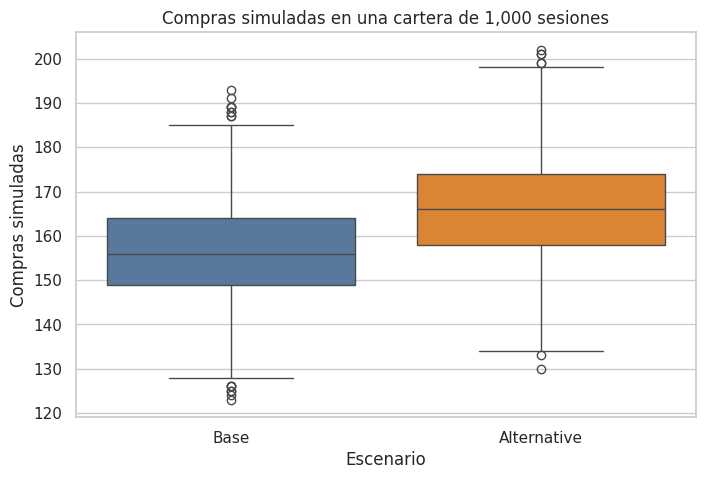

In [17]:
portfolio_plot = pd.DataFrame({
    "Base": portfolio_base,
    "Alternative": portfolio_alternative
})

plt.figure(figsize=(8, 5))
sns.boxplot(data=portfolio_plot, palette=["#4C78A8", "#F58518"])
plt.title("Compras simuladas en una cartera de 1,000 sesiones")
plt.xlabel("Escenario")
plt.ylabel("Compras simuladas")
plt.show()

### Interpretación

La simulación de la cartera combina una ecuación estructurada —sesiones por tasa de compra— con un componente incierto —la ocurrencia individual de una compra—. La diferencia entre los promedios permite estimar el efecto esperado del escenario, mientras que los percentiles muestran la variación que podría observarse aun manteniendo las mismas probabilidades.

## 9. Principales hallazgos

In [18]:
overall_purchase_rate = df_copy["Revenue_num"].mean() * 100
low_rate = navigation_profile.loc["Baja", "purchase_rate_pct"]
high_rate = navigation_profile.loc["Alta", "purchase_rate_pct"]
portfolio_gain = portfolio_alternative.mean() - portfolio_base.mean()

print(
    f"1. La tasa general de compra fue de {overall_purchase_rate:.2f}%. "
    f"Por nivel de navegación, pasó de {low_rate:.2f}% en el grupo bajo "
    f"a {high_rate:.2f}% en el grupo alto."
)

print(
    f"2. En el escenario determinista, una mejora de {improvement_pp} puntos "
    f"porcentuales produciría {additional_expected_purchases:.0f} compras "
    f"adicionales por cada {sessions_scenario:,} sesiones de baja navegación."
)

print(
    f"3. En la cartera simulada de {portfolio_size:,} sesiones, el escenario "
    f"alternativo generó en promedio {portfolio_gain:.2f} compras adicionales, "
    "aunque el resultado varió entre simulaciones."
)

1. La tasa general de compra fue de 15.63%. Por nivel de navegación, pasó de 6.96% en el grupo bajo a 23.18% en el grupo alto.
2. En el escenario determinista, una mejora de 3 puntos porcentuales produciría 30 compras adicionales por cada 1,000 sesiones de baja navegación.
3. En la cartera simulada de 1,000 sesiones, el escenario alternativo generó en promedio 9.53 compras adicionales, aunque el resultado varió entre simulaciones.


## 10. Conclusiones

El análisis permitió transformar las variables originales en indicadores útiles para describir el ritmo y la concentración de la navegación. Los resultados históricos muestran diferencias en el porcentaje de compra entre los niveles de navegación, lo que permite construir escenarios con una base observable.

El escenario determinista resume el efecto promedio de una mejora hipotética, mientras que la simulación muestra que el resultado real puede variar. Por ello, los resultados deben interpretarse como un rango de posibilidades y no como una cantidad garantizada de compras.

Finalmente, el escenario alternativo no demuestra que aumentar la interacción produzca por sí mismo más compras. Su utilidad consiste en estimar qué podría ocurrir si una estrategia lograra elevar la tasa de compra del grupo de baja navegación, manteniendo constantes las demás condiciones.